In [9]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline
import seaborn as sns


In [10]:
# Each CSV File is organized like this
df = pd.read_csv('/content/CLEAN_House1.csv', index_col=0, parse_dates=True)
df.head()


,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9,Issues
Time,,,,,,,,,,,,
2013-10-09 13:06:17,1381323977,523,74,0,69,0,0,0,0,0,1,0
2013-10-09 13:06:31,1381323991,526,75,0,69,0,0,0,0,0,1,0
2013-10-09 13:06:46,1381324006,540,74,0,68,0,0,0,0,0,1,0
2013-10-09 13:07:01,1381324021,532,74,0,68,0,0,0,0,0,1,0
2013-10-09 13:07:15,1381324035,540,74,0,69,0,0,0,0,0,1,0


In [11]:
# Vizualização de uso de diferentes equipamentos em diferentes horas do dia
by_hours_df = df.iloc[:, 2:].groupby(df.index.hour).mean()

by_hours_df = by_hours_df.rename(index=str, columns={
    "Appliance1":"Geladeira",
    "Appliance2":"Congelador Horizontal",
    "Appliance3":"Congelador Vertical",
    "Appliance4":"Secadora de Roupas",
    "Appliance5":"Máquina de lavar roupas",
    "Appliance6":"Máquina lavar louças",
    "Appliance7":"Computador",
    "Appliance8":"Televisão",
    "Appliance9":"Aquecedor elétrico"
})

by_hours_df


,Geladeira,Congelador Horizontal,Congelador Vertical,Secadora de Roupas,Máquina de lavar roupas,Máquina lavar louças,Computador,Televisão,Aquecedor elétrico,Issues
Time,,,,,,,,,,
0,17.967700,15.320134,28.968271,0.327639,0.147507,0.069081,0.543728,3.676707,172.103848,0.003519
1,16.247617,15.657914,28.050405,0.212499,0.638069,1.823558,0.016567,4.057490,267.072942,0.003461
2,16.104938,15.505595,28.603671,0.131419,2.995836,29.700860,0.011979,2.944218,275.950413,0.004839
3,14.026211,15.292279,27.363581,0.167376,8.405016,41.973217,0.009081,1.508138,273.814176,0.006128
4,16.270316,15.208325,26.600665,0.420622,22.648294,41.886251,0.009663,0.132073,269.038109,0.009492
5,15.379377,15.199009,27.249937,1.148294,23.596861,15.994264,0.009324,0.051579,153.272753,0.025934
6,16.193383,15.298864,27.738394,3.181931,7.219130,1.942729,0.048259,0.351114,71.343467,0.033998
7,19.023838,15.888030,28.773303,2.211588,4.129391,1.046842,0.452750,2.505454,26.204158,0.014953
8,17.365256,16.501105,28.061849,0.809822,13.300646,6.406754,0.715881,3.578460,13.645716,0.006921


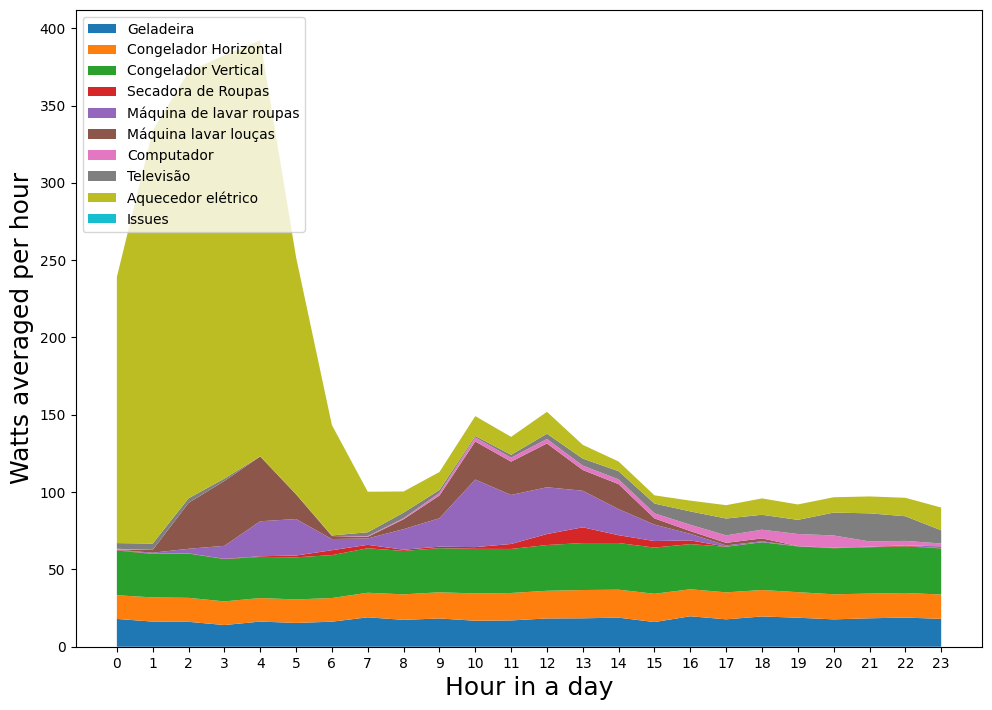

In [12]:
# Set size of plot
fig, ax = plt.subplots()
fig.set_size_inches(11.7, 8.27)
# Stackplot
ax.stackplot(list(range(24)), np.transpose(by_hours_df.values), labels=by_hours_df.columns.values)
plt.xlabel('Hour in a day', fontsize=18)
plt.ylabel('Watts averaged per hour', fontsize=18)
plt.xticks(np.arange(0, 24, 1.0))
ax.legend(loc=2)


Text(0.5, 1.0, 'Televisão')

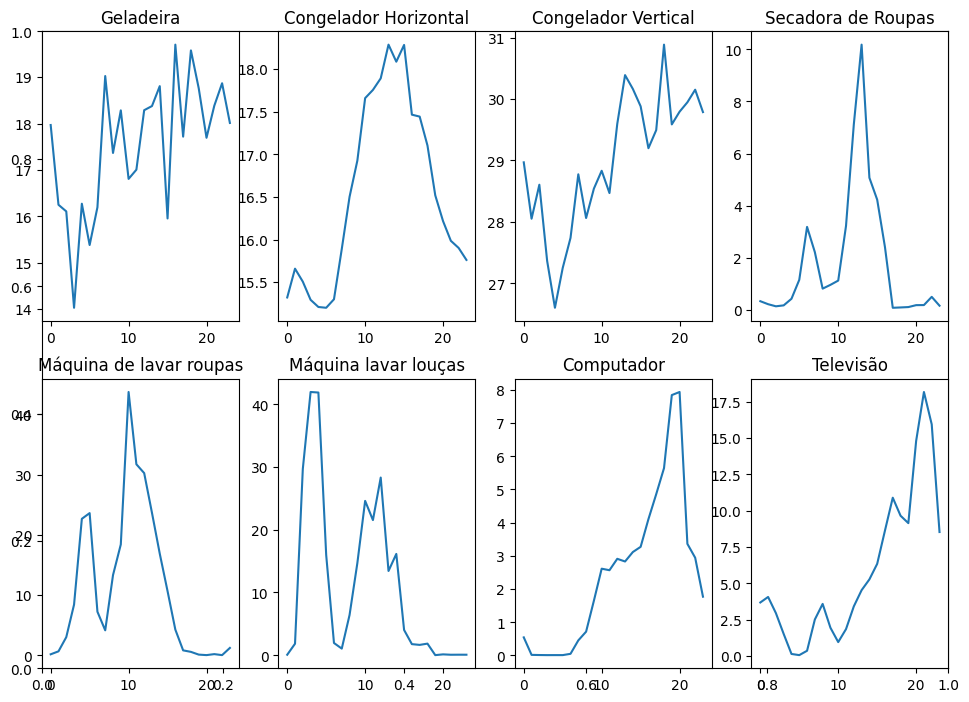

In [13]:
fig, ax = plt.subplots()
fig.set_size_inches(11.7, 8.27)

plt.subplot(241)
# Usage of various appliances
plt.plot(list(range(24)), by_hours_df['Geladeira'].values)
plt.title('Geladeira')

plt.subplot(242)
# Usage of various appliances
plt.plot(list(range(24)), by_hours_df['Congelador Horizontal'].values)
plt.title('Congelador Horizontal')

plt.subplot(243)
# Usage of various appliances
plt.plot(list(range(24)), by_hours_df['Congelador Vertical'].values)
plt.title('Congelador Vertical')

plt.subplot(244)
# Usage of various appliances
plt.plot(list(range(24)), by_hours_df['Secadora de Roupas'].values)
plt.title('Secadora de Roupas')

plt.subplot(245)
# Usage of various appliances
plt.plot(list(range(24)), by_hours_df['Máquina de lavar roupas'].values)
plt.title('Máquina de lavar roupas')

plt.subplot(246)
# Usage of various appliances
plt.plot(list(range(24)), by_hours_df['Máquina lavar louças'].values)
plt.title('Máquina lavar louças')

plt.subplot(247)
# Usage of various appliances
plt.plot(list(range(24)), by_hours_df['Computador'].values)
plt.title('Computador')

plt.subplot(248)
# Usage of various appliances
plt.plot(list(range(24)), by_hours_df['Televisão'].values)
plt.title('Televisão')
